# YOLO26: find objects in urban images
**Beginner lab · Xiaojiang Li · University of Pennsylvania**

We will teach a pretrained model to find street trees, then check its predictions on images it has not trained on. You can replace trees with your own class later.

**You will learn:** inspect LabelMe annotations → split images → fine-tune → measure accuracy → inspect mistakes.

**Before starting:** choose **Runtime → Change runtime type → T4 GPU**. Run cells from top to bottom. First run the 3-epoch practice experiment; it checks the workflow, not final accuracy. A GPU runtime uses your Colab quota. Save your work before disconnecting.

**Two tasks, two kinds of labels**

| LabelMe shape | What we can learn | Setting |
|---|---|---|
| Rectangle around an object | A bounding box and object class | `TASK="detect"` (default) |
| Polygon tracing an object's outline | A bounding box, class, and instance mask | `TASK="segment"` (extension) |

The supplied tree dataset contains rectangles. A rectangle is **not** a tree silhouette. We never invent segmentation targets from rectangles.

**Pause and discuss:** Is your question “How many visible trees?” or “Which pixels belong to each tree?”

## How this model works
YOLO predicts objects through a single detector network. Its Python interface handles the training loop for us. We use the small **nano** model to limit classroom compute.

With rectangles we load `yolo26n.pt`; with polygons and `TASK="segment"` we load `yolo26n-seg.pt`. The checkpoint and label format change together. The two notebooks share data preparation and the final evaluator.

## 1. Install a few packages
Colab already supplies matching PyTorch and Torchvision packages; we keep those. If installation asks you to restart the session, restart it and continue from the next cell. We record installed versions with the results.

In [ ]:
%pip install -q "torchmetrics==1.9.0" "pycocotools==2.0.11" "Pillow>=10" "matplotlib>=3.8" "ultralytics==8.4.170"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 983.4/983.4 kB 26.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 62.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 96.0/96.0 kB 7.5 MB/s eta 0:00:00


In [ ]:
from pathlib import Path
from datetime import datetime
import json, random, sys, subprocess, shutil, zipfile, urllib.request, hashlib
import numpy as np
import torch, torchvision
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
from IPython.display import display

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('PyTorch:', torch.__version__, '| Torchvision:', torchvision.__version__, '| Device:', DEVICE)
if DEVICE.type == 'cpu':
    print('CPU works for checking data, but select a T4 GPU before training.')
WORK = Path('/content/urban-vision-lessons')
WORK.mkdir(parents=True, exist_ok=True)

PyTorch: 2.11.0+cu130 | Torchvision: 0.26.0+cu130 | Device: cuda


## 2. Choose the task and data
Only edit this small settings cell for your first experiment. Use the course data now; later set `USE_COURSE_DATA=False` and put your images and LabelMe JSON files in the Drive folder below.

**Labeling rules:** label every visible target instance consistently; use one shape per object; do not add a background label. Save an empty `shapes` list only for an image you verified has no target objects. Images without JSON are ignored. For segmentation, draw simple polygons without holes or multipart groups.

In [ ]:
TASK = 'detect'              # 'segment' requires your own polygon labels.
USE_COURSE_DATA = True
MY_LABELME_FOLDER = '/content/drive/MyDrive/urban-labelme'
SPLIT_FILE = None             # Optional path to a JSON split assignment (explained below).
EPOCHS = 3                   # Practice run; try 20 later after inspecting results.
IMAGE_SIZE = 640
BATCH_SIZE = 2               # If GPU memory runs out, reduce to 1.

if USE_COURSE_DATA:
    archive = WORK/'course-data.zip'
    if not archive.exists():
        urllib.request.urlretrieve(
            'https://utilitiesfiles.s3.us-east-1.amazonaws.com/penn-class/ai-urban-sustainability/data/traindata_clean.zip', archive)
    RAW = WORK/'course-data'
    RAW.mkdir(exist_ok=True)
    with zipfile.ZipFile(archive) as z:
        for item in z.infolist():
            if not (RAW/item.filename).resolve().is_relative_to(RAW.resolve()):
                raise ValueError('Unsafe archive path')
        z.extractall(RAW)
else:
    from google.colab import drive
    drive.mount('/content/drive')
    RAW = Path(MY_LABELME_FOLDER)
assert RAW.is_dir(), f'Folder not found: {RAW}'
RUN = WORK/('yolo' + '-' + TASK + '-' + datetime.now().strftime('%Y%m%d-%H%M%S-%f'))
RUN.mkdir()
(RUN/'environment-freeze.txt').write_text(subprocess.check_output([sys.executable,'-m','pip','freeze'],text=True))
print('Results folder:', RUN)

Results folder: /content/urban-vision-lessons/yolo-detect-20261005-112453-179393


## 3. Read and check the annotations
**Helper cell — run it; no edits needed.** This code checks image sizes, labels, and geometry before training.

For this teaching dataset, an exact duplicate is removed by retaining the first filename in sorted order and its annotations. Out-of-bounds rectangles are clipped to the image. Every adjustment is printed and saved; source files are unchanged. Review duplicate annotation differences before research use. Polygon errors stop the workflow rather than being silently repaired.

In [ ]:
"""Shared LabelMe preparation for the two beginner notebooks (embedded in each)."""
import json
import hashlib
import random
from collections import Counter
from pathlib import Path
import numpy as np
from PIL import Image, ImageDraw


def load_labelme(root, task='detect'):
    root = Path(root)
    if task not in ('detect', 'segment'):
        raise ValueError("TASK must be 'detect' or 'segment'.")
    records, warnings, seen = [], [], {}
    shape_counts = Counter()
    for path in sorted(root.rglob('*.json')):
        if '__MACOSX' in path.parts or path.name.startswith('._'):
            continue
        data = json.loads(path.read_text())
        if 'shapes' not in data or 'imagePath' not in data:
            continue
        name = Path(data['imagePath'].replace('\\', '/')).name
        image_path = path.parent / name
        if not image_path.is_file():
            raise ValueError(f'{path.name}: save the image beside its JSON file.')
        with Image.open(image_path) as im:
            if im.getexif().get(274, 1) != 1:
                raise ValueError(f'{name}: normalize image orientation before annotating.')
            rgb = im.convert('RGB'); w, h = rgb.size
            digest = hashlib.sha256(str(rgb.size).encode() + rgb.tobytes()).hexdigest()
        if (w, h) != (data.get('imageWidth'), data.get('imageHeight')):
            raise ValueError(f'{name}: image and annotation dimensions disagree.')
        if digest in seen:
            warnings.append(f'{name}: exact duplicate of {seen[digest]}; retained the first image and its annotations only. Review annotation differences before research use.')
            continue
        seen[digest] = name
        objects, groups = [], set()
        for shape in data['shapes']:
            kind = shape.get('shape_type', 'polygon'); shape_counts[kind] += 1
            label = shape['label'].strip()
            if not label or label.lower() in ('background', '__background__'):
                raise ValueError(f'{name}: use object names only, no background label.')
            pts = np.asarray(shape['points'], dtype=float)
            if pts.ndim != 2 or pts.shape[1] != 2 or not np.isfinite(pts).all():
                raise ValueError(f'{name}: invalid coordinates.')
            group = shape.get('group_id')
            if group is not None:
                key = (label, group)
                if key in groups:
                    raise ValueError(f'{name}: multipart objects need a separate conversion policy; use one shape per object.')
                groups.add(key)
            polygon = None
            if kind == 'rectangle':
                if task == 'segment':
                    raise ValueError('Segmentation needs polygons tracing object boundaries. Your data contains rectangles; use TASK="detect".')
                if len(pts) != 2:
                    raise ValueError(f'{name}: rectangle must have two opposite corners.')
                clipped = np.clip(pts, [0, 0], [w, h])
                if not np.array_equal(clipped, pts):
                    warnings.append(f'{name}: clipped rectangle to image boundary (original JSON unchanged).')
                pts = clipped
            elif kind == 'polygon':
                if len(pts) > 1 and np.array_equal(pts[0], pts[-1]):
                    pts = pts[:-1]
                if len(np.unique(pts, axis=0)) < 3:
                    raise ValueError(f'{name}: polygon needs three distinct points.')
                if (pts < 0).any() or (pts > [w, h]).any():
                    raise ValueError(f'{name}: polygon outside image; correct it in LabelMe.')
                area = abs(np.dot(pts[:,0], np.roll(pts[:,1],1))-np.dot(pts[:,1], np.roll(pts[:,0],1)))/2
                if area < 1:
                    raise ValueError(f'{name}: degenerate polygon.')
                polygon = pts.tolist()
            else:
                raise ValueError(f'{name}: unsupported {kind}; use rectangles or polygons.')
            x1,y1 = pts.min(axis=0); x2,y2 = pts.max(axis=0)
            if x2 <= x1 or y2 <= y1:
                raise ValueError(f'{name}: zero-area box.')
            objects.append({'label':label,'box':[float(x1),float(y1),float(x2),float(y2)],'polygon':polygon})
        records.append({'id':path.relative_to(root).as_posix(), 'image':str(image_path.resolve()),
                        'width':w,'height':h,'objects':objects,'sha256':digest})
    if len(records) < 3:
        raise ValueError('Need at least 3 annotated images; a useful experiment needs many more.')
    names = sorted({o['label'] for r in records for o in r['objects']})
    if not names:
        raise ValueError('No labeled objects found.')
    print(f'{len(records)} images; classes: {names}; shapes: {dict(shape_counts)}')
    for warning in warnings: print('Annotation note:', warning)
    return records, names, warnings


def make_splits(records, names, seed=42, split_file=None):
    ids = sorted(r['id'] for r in records)
    if split_file:
        assignment = json.loads(Path(split_file).read_text())
        if set(assignment) != set(ids) or set(assignment.values()) != {'train','val','test'}:
            raise ValueError('Split file must assign every annotation to train, val, or test, with all three populated.')
    else:
        random.Random(seed).shuffle(ids)
        n = max(1, round(len(ids)*0.15))
        assignment = {key: ('test' if i<n else 'val' if i<2*n else 'train') for i,key in enumerate(ids)}
        print('Demo split: random images. For urban research, supply splits grouped by street/site.')
    splits = {s: [r for r in records if assignment[r['id']] == s] for s in ['train','val','test']}
    for s, rows in splits.items():
        counts = Counter(o['label'] for r in rows for o in r['objects'])
        print(s, len(rows), 'images;', dict(counts), 'objects')
        missing = set(names)-set(counts)
        if missing and s == 'train': raise ValueError(f'Training lacks {missing}; revise split or add examples.')
        if missing: print(f'Warning: {s} has no examples of {sorted(missing)}; metrics cannot evaluate them.')
        if not counts: raise ValueError(f'{s} has no objects; revise split before evaluating AP.')
    return splits, assignment


def draw_ground_truth(record):
    im = Image.open(record['image']).convert('RGB'); draw = ImageDraw.Draw(im)
    for obj in record['objects']:
        draw.rectangle(obj['box'], outline='lime', width=3)
        if obj['polygon']:
            points = [tuple(p) for p in obj['polygon']]
            draw.line(points+[points[0]], fill='cyan', width=2)
        draw.text(tuple(obj['box'][:2]), obj['label'], fill='red')
    return im


def export_yolo(splits, names, output, task):
    output = Path(output)
    if output.exists(): raise ValueError('Choose a new YOLO export folder; existing data is protected.')
    for split, rows in splits.items():
        (output/'images'/split).mkdir(parents=True)
        (output/'labels'/split).mkdir(parents=True)
        for i,r in enumerate(rows):
            with Image.open(r['image']) as im: im.convert('RGB').save(output/'images'/split/f'{i:06}.png')
            lines=[]
            for o in r['objects']:
                if task == 'detect':
                    x1,y1,x2,y2 = o['box']; w,h=r['width'],r['height']
                    values=[(x1+x2)/2/w,(y1+y2)/2/h,(x2-x1)/w,(y2-y1)/h]
                else:
                    if o['polygon'] is None: raise ValueError('True polygons required for segmentation.')
                    values=[v for x,y in o['polygon'] for v in (x/r['width'],y/r['height'])]
                lines.append(str(names.index(o['label']))+' '+' '.join(f'{v:.8f}' for v in values))
            (output/'labels'/split/f'{i:06}.txt').write_text('\n'.join(lines))
    data={'path':str(output.resolve()),'train':'images/train','val':'images/val','test':'images/test','names':names}
    # JSON is valid YAML and preserves punctuation in class names and paths.
    (output/'data.yaml').write_text(json.dumps(data, indent=2))
    return output/'data.yaml'

156 images; classes: ['tree']; shapes: {'rectangle': 443}
Annotation note: 100.jpg: clipped rectangle to image boundary (original JSON unchanged).
Annotation note: 270.jpg: clipped rectangle to image boundary (original JSON unchanged).
Annotation note: 625.jpg: exact duplicate of 619.jpg; retained the first image and its annotations only. Review annotation differences before research use.
Object classes: ['tree']


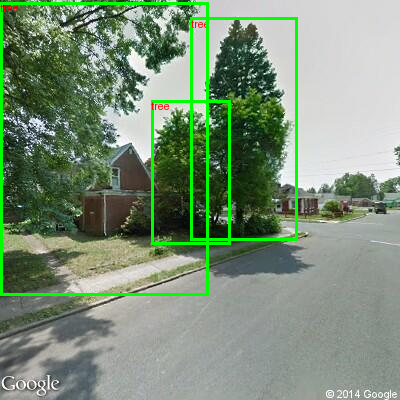

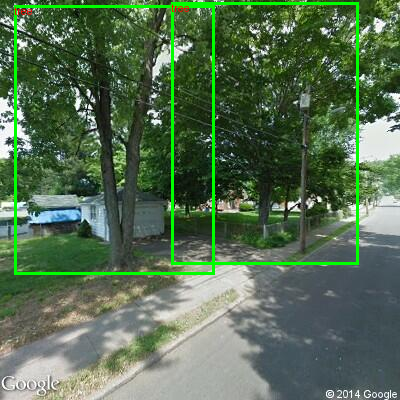

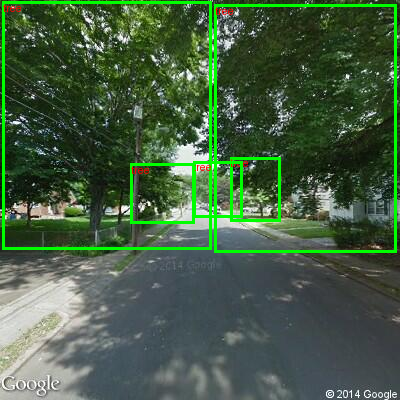

In [ ]:
records, CLASS_NAMES, annotation_notes = load_labelme(RAW, TASK)
print('Object classes:', CLASS_NAMES)
# Both models use the same sorted class order. Background is handled internally.
for record in records[:3]:
    preview = draw_ground_truth(record)
    preview.thumbnail((650, 450)); display(preview)

## 4. Keep training and evaluation separate
- **Training:** images used to update model weights.
- **Validation:** images used to select the best checkpoint and settings.
- **Test:** untouched images used once for final reporting.

Both notebooks use the same seed, sorted filenames, and split code, so the course data produces the same split. The saved `split_assignment.json` can be reused through `SPLIT_FILE`.

The default random split is a classroom demonstration. For an urban study, group all images from the **same street, site, panorama, or capture sequence** into one split. Otherwise nearly identical scenes can inflate apparent accuracy. An explicit split file maps each printed relative annotation ID to `train`, `val`, or `test`.

Example: `{"siteA/001.json":"train", "siteB/002.json":"val", "siteC/003.json":"test"}`; include every retained annotation. Aim for approximately 70/15/15, with enough examples of every class in each split.

In [ ]:
splits, assignment = make_splits(records, CLASS_NAMES, SEED, SPLIT_FILE)
(RUN/'split_assignment.json').write_text(json.dumps(assignment, indent=2))
manifest = [{k:v for k,v in r.items() if k != 'image'} for r in records]
(RUN/'dataset_manifest.json').write_text(json.dumps(manifest, indent=2))
(RUN/'annotation_notes.json').write_text(json.dumps(annotation_notes, indent=2))
(RUN/'lesson_config.json').write_text(json.dumps({
    'task': TASK, 'classes': CLASS_NAMES, 'epochs': EPOCHS, 'image_size': IMAGE_SIZE,
    'batch_size': BATCH_SIZE, 'seed': SEED, 'split_method': 'explicit' if SPLIT_FILE else 'random demo'
}, indent=2))
print('Example annotation IDs:', [r['id'] for r in records[:3]])

Demo split: random images. For urban research, supply splits grouped by street/site.
train 110 images; {'tree': 312} objects
val 23 images; {'tree': 65} objects
test 23 images; {'tree': 66} objects
Example annotation IDs: ['traindata_clean/100.json', 'traindata_clean/101.json', 'traindata_clean/102.json']


## 5. Shared prediction and evaluation helpers
**Helper cell — run it; no edits needed.** Both lessons use TorchMetrics' COCO-style evaluation on original image coordinates, with at most 100 predictions per image and a low score cutoff of 0.001. The display threshold later is deliberately separate.

**AP** summarizes precision and recall across confidence thresholds. **AP50** accepts overlap (IoU) of at least 0.50. **AP50–95** averages stricter overlap thresholds from 0.50 to 0.95. Scores are on a 0–1 scale. A confidence of 0.99 on one object is not “99% accuracy.”

In [ ]:
"""Model helpers embedded in the notebooks; no separate upload required."""
import torch
import numpy as np
from PIL import Image, ImageDraw
from torchvision.transforms.functional import pil_to_tensor
from torchmetrics.detection.mean_ap import MeanAveragePrecision


def target_for_record(record, names, task, label_offset=0):
    objects = record['objects']
    target = {'boxes':torch.tensor([o['box'] for o in objects],dtype=torch.float32).reshape(-1,4),
              'labels':torch.tensor([names.index(o['label'])+label_offset for o in objects],dtype=torch.int64)}
    if task == 'segment':
        masks=[]
        for o in objects:
            if o['polygon'] is None: raise ValueError('Masks need polygon labels.')
            mask=Image.new('L',(record['width'],record['height']),0)
            ImageDraw.Draw(mask).polygon([tuple(p) for p in o['polygon']],fill=1)
            masks.append(torch.from_numpy(np.array(mask,dtype=bool)))
        target['masks']=torch.stack(masks) if masks else torch.zeros((0,record['height'],record['width']),dtype=torch.bool)
    return target


def predict_yolo(model, record, device, task, image_size=640):
    result=model.predict(record['image'],device=device,imgsz=image_size,conf=0.001,
                         max_det=100,retina_masks=True,verbose=False)[0]
    pred={'boxes':result.boxes.xyxy.cpu(), 'labels':result.boxes.cls.cpu().long(), 'scores':result.boxes.conf.cpu()}
    if task == 'segment':
        pred['masks']=(result.masks.data.cpu()>=0.5) if result.masks is not None else torch.zeros((0,record['height'],record['width']),dtype=torch.bool)
    return pred


def evaluate_predictions(rows, names, task, predict_one):
    # Both lessons use this same COCO-style evaluator on ORIGINAL image coordinates.
    # Retain low-score detections for AP; the display threshold is separate.
    metrics={'box':MeanAveragePrecision(iou_type='bbox',class_metrics=True)}
    if task == 'segment': metrics['mask']=MeanAveragePrecision(iou_type='segm',class_metrics=True)
    for r in rows:
        prediction=predict_one(r); truth=target_for_record(r,names,task)
        for metric in metrics.values(): metric.update([prediction],[truth])
    report={}
    for prefix,metric in metrics.items():
        result=metric.compute()
        for key in ['map','map_50','map_75','mar_100']:
            report[prefix+'_'+key]=float(result[key])
        report[prefix+'_per_class_AP']={names[int(c)]:float(v) for c,v in zip(result['classes'].reshape(-1),result['map_per_class'].reshape(-1))}
    return report


def draw_prediction(record, prediction, names, threshold=0.5):
    im=Image.open(record['image']).convert('RGB')
    keep=prediction['scores']>=threshold
    if 'masks' in prediction:
        pixels=np.array(im).copy()
        for mask in prediction['masks'][keep].numpy(): pixels[mask]=(0.65*pixels[mask]+0.35*np.array([0,255,255])).astype(np.uint8)
        im=Image.fromarray(pixels)
    draw=ImageDraw.Draw(im)
    for box,label,score in zip(prediction['boxes'][keep],prediction['labels'][keep],prediction['scores'][keep]):
        draw.rectangle(box.tolist(),outline='red',width=3)
        draw.text(tuple(box[:2].tolist()),f'{names[int(label)]}: {float(score):.2f}',fill='red')
    return im, int(keep.sum())

## 6. Export the labels for YOLO
YOLO detection labels contain class ID, box center, width, and height, divided by image width/height. Class IDs start at 0; there is no explicit background class. Segmentation labels instead contain normalized polygon vertices.

In [ ]:
DATA_YAML = export_yolo(splits, CLASS_NAMES, RUN/'yolo-data', TASK)
example_label = sorted((RUN/'yolo-data/labels/train').glob('*.txt'))[0]
print('Example label file:', example_label.name)
print(example_label.read_text())

Example label file: 000000.txt
0 0.28590426 0.34906915 0.50132979 0.67287234
0 0.66156915 0.33377660 0.46808511 0.65558511


## 7. Fine-tune a pretrained YOLO model
The library handles the training loop. We still choose the data, epochs, image size, and batch size, and must inspect results critically. The `.pt` file supplies pretrained weights; an architecture file alone would start from scratch.

For this introductory comparison, extra YOLO mosaic and color augmentation are disabled; horizontal flipping remains. This reduces differences between the exercises, but the models still have different optimizers and training recipes. Equal epochs do not imply equal compute.

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
New https://pypi.org/project/ultralytics/8.4.173 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.170 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/urban-vision-lessons/yolo-detect-20261005-112453-179393/yolo-data/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dl

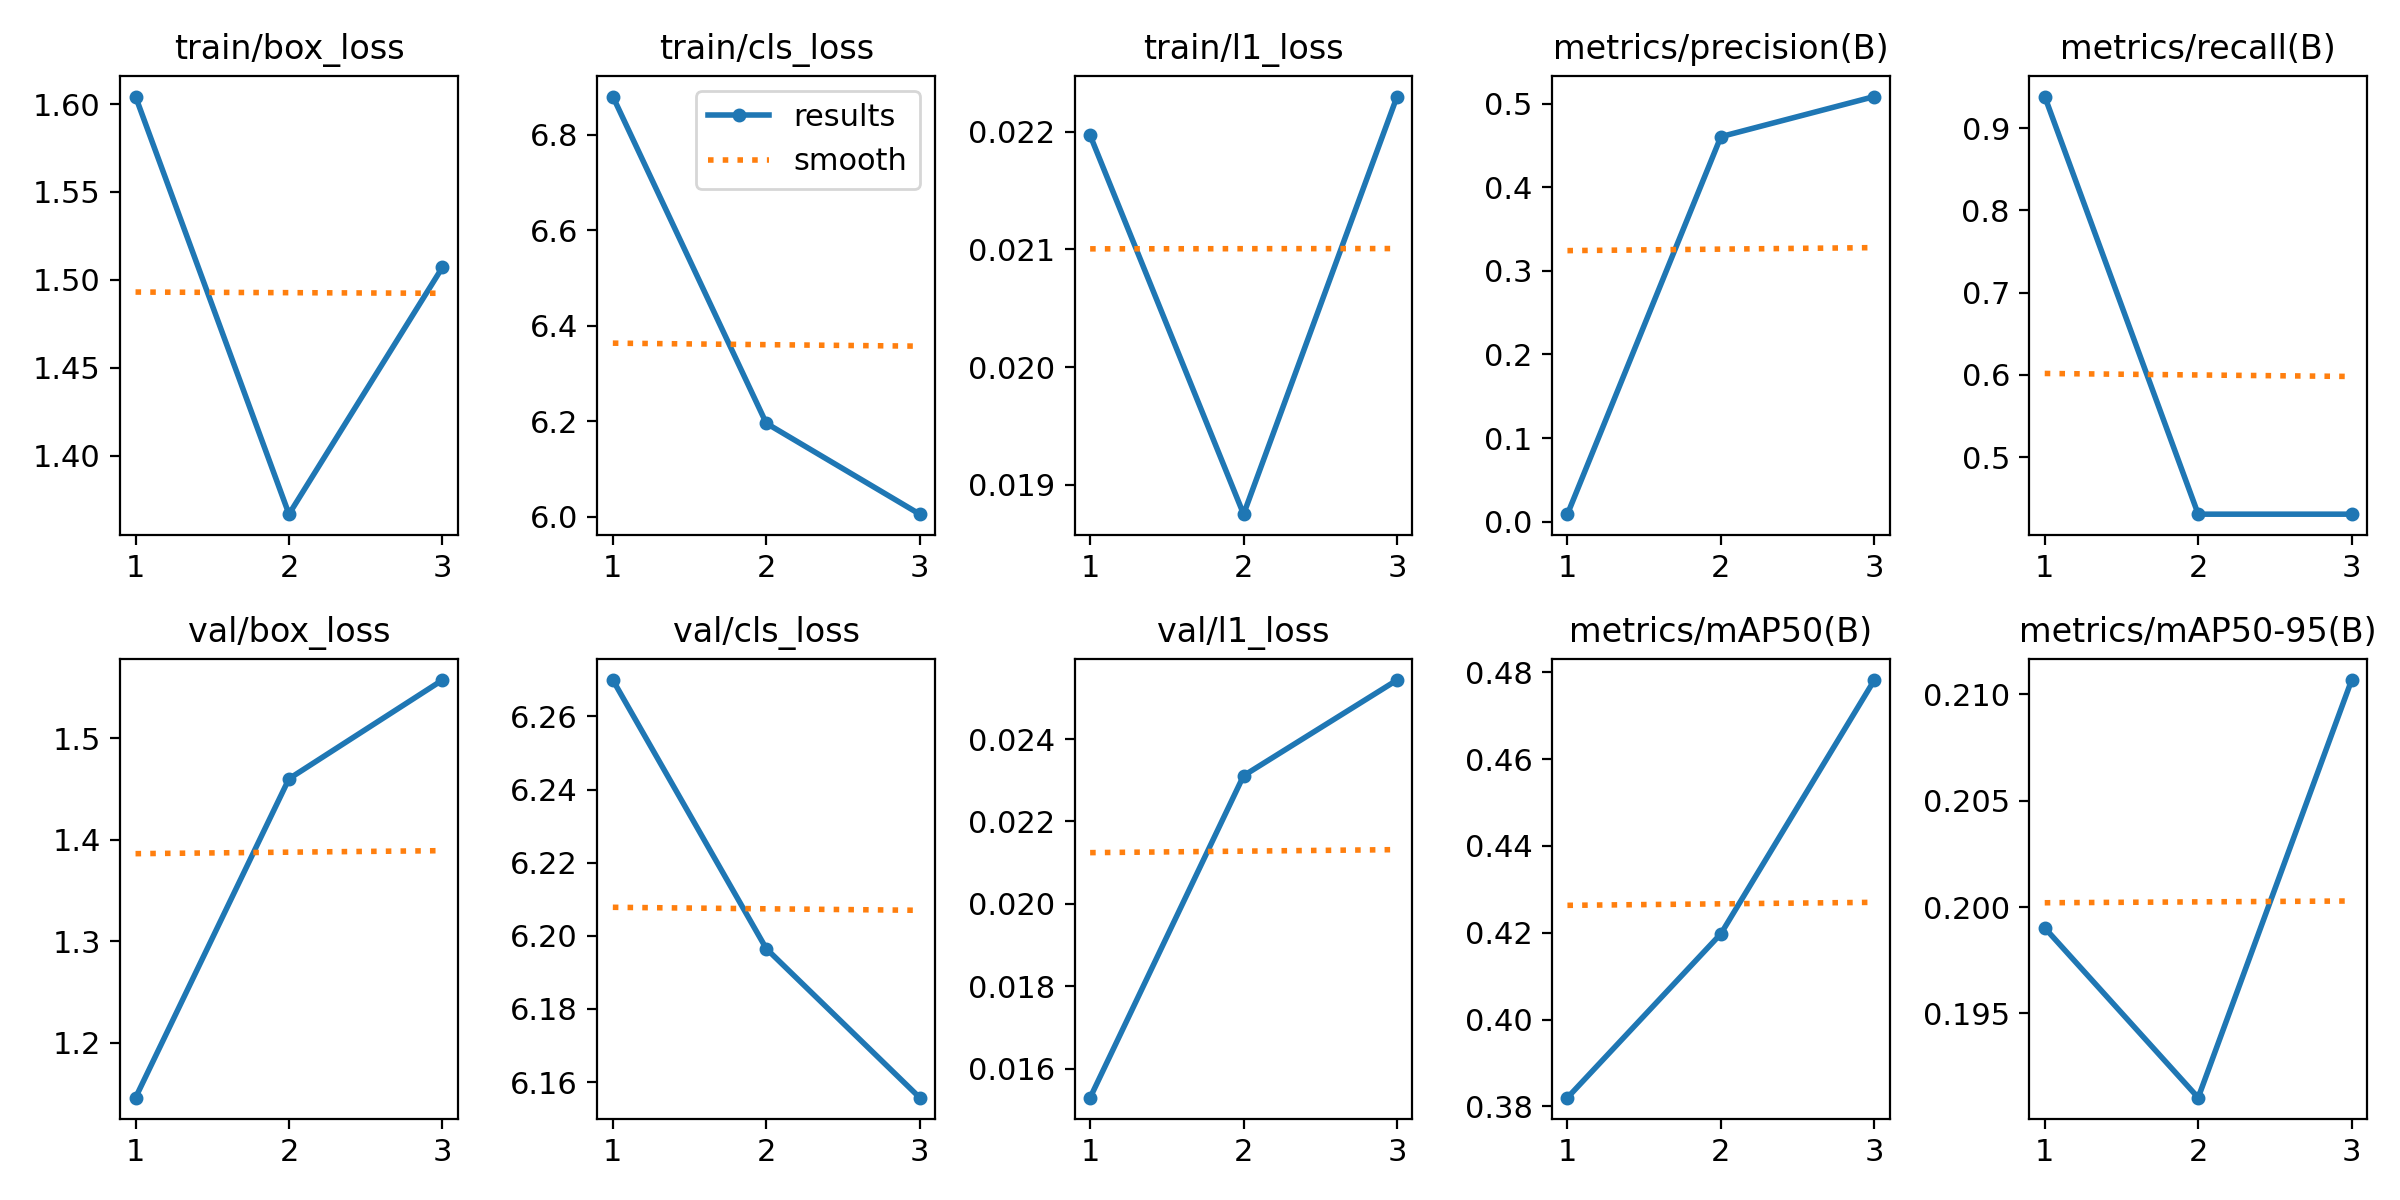

In [ ]:
from ultralytics import YOLO
MODEL_NAME = 'yolo26n-seg.pt' if TASK == 'segment' else 'yolo26n.pt'
train_model = YOLO(MODEL_NAME)
train_model.train(
    data=str(DATA_YAML), epochs=EPOCHS, imgsz=IMAGE_SIZE, batch=BATCH_SIZE,
    device=0 if DEVICE.type == 'cuda' else 'cpu', workers=0, seed=SEED,
    project=str(RUN), name='training', exist_ok=False, patience=10,
    mosaic=0.0, mixup=0.0, copy_paste=0.0, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
    degrees=0.0, translate=0.0, scale=0.0, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.5, plots=True)
TRAIN_RUN = Path(train_model.trainer.save_dir)
BEST = TRAIN_RUN/'weights/best.pt'
assert BEST.is_file(), 'No checkpoint found; inspect training errors above.'
if (TRAIN_RUN/'results.png').exists(): display(Image.open(TRAIN_RUN/'results.png'))

## 8. Reload the best model and evaluate validation data
YOLO selects `best.pt` using its built-in validation fitness. We reload it, then use the same independent evaluator as the Mask R-CNN lesson for the reported comparison. Its AP values may differ slightly from the library's built-in results because evaluation details differ.

In [ ]:
best_model = YOLO(str(BEST))
predict_one = lambda r: predict_yolo(best_model, r, 0 if DEVICE.type == 'cuda' else 'cpu', TASK, IMAGE_SIZE)
validation_metrics = evaluate_predictions(splits['val'], CLASS_NAMES, TASK, predict_one)
print(json.dumps(validation_metrics, indent=2))
(RUN/'validation_metrics.json').write_text(json.dumps(validation_metrics, indent=2))

{
  "box_map": 0.21668528020381927,
  "box_map_50": 0.4653865694999695,
  "box_map_75": 0.17542707920074463,
  "box_mar_100": 0.5076923370361328,
  "box_per_class_AP": {
    "tree": 0.21668528020381927
  }
}


207

## 9. Final test — after choosing your settings
Run this cell after deciding your model settings using validation. Do not tune using test results. The metrics cover the entire test split, not a single attractive example. Mask metrics appear only when genuine polygon labels are used.

For comparison, use the same task, data, class definitions, split assignment, image-size setting, and evaluator in both notebooks. Also record training time and hardware. Different resize/augmentation/training recipes mean this is a classroom comparison, not a controlled architecture benchmark.

In [ ]:
test_metrics = evaluate_predictions(splits['test'], CLASS_NAMES, TASK, predict_one)
print(json.dumps(test_metrics, indent=2))
(RUN/'test_metrics.json').write_text(json.dumps(test_metrics, indent=2))

{
  "box_map": 0.2132192999124527,
  "box_map_50": 0.4314788579940796,
  "box_map_75": 0.20617765188217163,
  "box_mar_100": 0.5166666507720947,
  "box_per_class_AP": {
    "tree": 0.2132192999124527
  }
}


205

## 10. Look at successes and failures
Left: annotation. Right: predictions. `DISPLAY_THRESHOLD` controls which predictions are shown; it does not retrain the model or change the AP calculation above.

An empty prediction is a valid outcome. Look for missed objects, false alarms, overlapping trees, small objects, and difficult lighting. Visible object counts in a few photos are not automatically a citywide estimate.

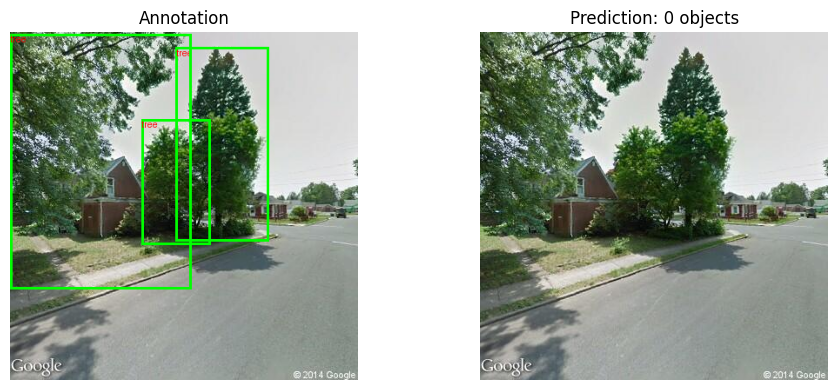

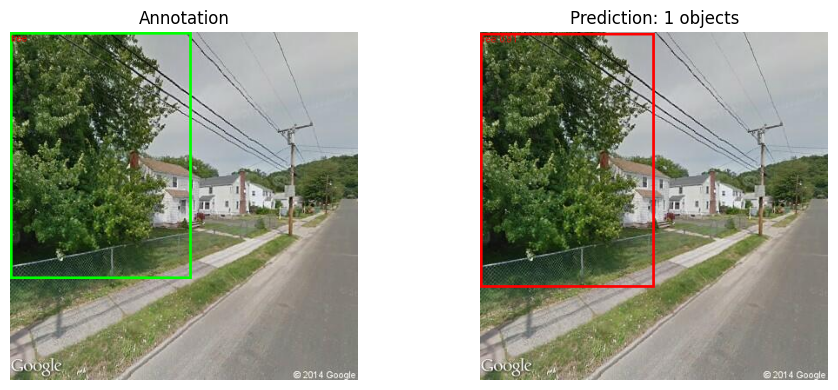

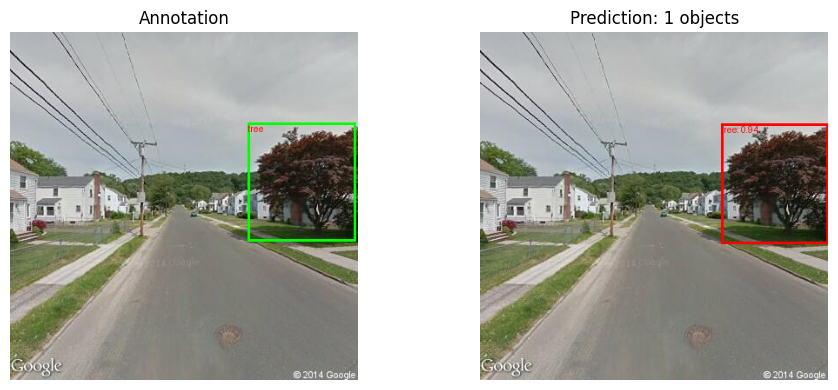

In [ ]:
DISPLAY_THRESHOLD = 0.5
for record in splits['test'][:3]:
    prediction = predict_one(record)
    predicted_image, count = draw_prediction(record, prediction, CLASS_NAMES, DISPLAY_THRESHOLD)
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].imshow(draw_ground_truth(record)); axes[0].set_title('Annotation')
    axes[1].imshow(predicted_image); axes[1].set_title(f'Prediction: {count} objects')
    for ax in axes: ax.axis('off')
    plt.tight_layout(); plt.show()

## 11. Save your work
Download the checkpoint, metrics, exact split, annotation audit, settings, and package versions before Colab disconnects. The labeled images themselves are not included; retain those separately. `best.pt` is model-specific: a Torchvision checkpoint and a YOLO checkpoint are not interchangeable.

Set `SAVE_TO_DRIVE=True` to also save the ZIP in `MyDrive/urban-vision-results`.

In [ ]:
bundle = RUN/'submission'; bundle.mkdir(exist_ok=True)
shutil.copy2(BEST, bundle/'best.pt')
for name in ['test_metrics.json','validation_metrics.json','history.json','split_assignment.json',
             'dataset_manifest.json','annotation_notes.json','lesson_config.json','environment-freeze.txt']:
    if (RUN/name).exists(): shutil.copy2(RUN/name, bundle/name)
archive_path = shutil.make_archive(str(RUN/'lesson-submission'), 'zip', bundle)
SAVE_TO_DRIVE = True
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    destination = Path('/content/drive/MyDrive/urban-vision-results')
    destination.mkdir(exist_ok=True)
    saved = destination/(RUN.name+'.zip')
    shutil.copy2(archive_path, saved)
    print('Saved:', saved)
from google.colab import files
files.download(archive_path)

MessageError: Error: credential propagation was unsuccessful